# Finitewave: hands-on cardiac electrophysiology

These examples progress from single-cell action potentials to two-dimensional tissue experiments and simulation on patient atrial geometry. Run the examples in order, as later steps reuse earlier definitions. Time is in milliseconds (ms), membrane voltage in millivolts (mV), and tissue spacing in millimeters (mm).

## 1. Single-cell modeling

### Environment setup

Install Finitewave, the Courtemanche atrial model, and visualization tools. For GPU execution, use a GPU runtime with a compatible JAX installation. Run installation once per environment and restart the runtime if requested.


In [ ]:
# Install packages into the active notebook kernel (internet access required).
%pip install git+https://github.com/finitewave/Courtemanche-finitewave-model.git@main
# Install packages into the active notebook kernel (internet access required).
%pip install git+https://github.com/finitewave/Finitewave.git@solvers
# Install packages into the active notebook kernel (internet access required).
%pip install git+https://github.com/finitewave/Finitewave-Tools@main
%pip install pyvista[jupyter]

  Cloning https://github.com/finitewave/Mitchell-Schaeffer-finitewave-model.git (to revision main) to /tmp/pip-req-build-qid0yqjg
  Running command git clone --filter=blob:none --quiet https://github.com/finitewave/Mitchell-Schaeffer-finitewave-model.git /tmp/pip-req-build-qid0yqjg
  Resolved https://github.com/finitewave/Mitchell-Schaeffer-finitewave-model.git to commit a94689db6544b1e12f86766c35d876400d5e6cd3
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Cloning https://github.com/finitewave/Courtemanche-finitewave-model.git (to revision main) to /tmp/pip-req-build-iedymixd
  Running command git clone --filter=blob:none --quiet https://github.com/finitewave/Courtemanche-finitewave-model.git /tmp/pip-req-build-iedymixd
  Resolved https://github.com/finitewave/Courtemanche-finitewave-model.git to commit 351c7d516ecdad2f5ce41ecf6dc9c82ead46b42f
  Installing build dependencies ... done
  Getting re

### Action potentials and ionic remodeling

Prepare three independent atrial cells: reference, remodeled, and reference with reduced potassium conductances (`gkr` and `gkur`). Each receives 30 pacing stimuli at a 1000 ms cycle length followed by 30 at 500 ms. The plot compares the final 1200 ms of their action potentials.


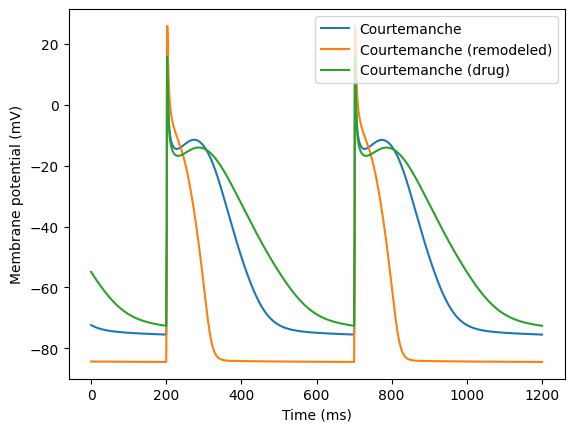

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import finitewave as fw


# Selected ionic remodeling: multipliers scale individual conductances or transport rates.
REMODELED_PARAMETERS = dict(
    gk1 = 2 * 0.09,
    gks = 2 * 0.129,
    gkur = 0.5 * 1.0,
    gcal = 0.45 * 0.1238,
    gto = 0.35 * 0.1652,
    ipcamax = 1.5 * 0.6,
    inacamax = 1.6 * 1600.0
)

# Set gKr and gKur to 10% of their reference values; other parameters stay as initialized.
DRUG_PARAMETERS = dict(
    gkr = 0.1 * 0.0294,
    gkur = 0.1 * 1.0,
)

# Prepacing history shared by the three single-cell comparisons (times in ms).
DT = 0.02
stim_prepacing = fw.StimSingleCell(dt=DT)
stim_prepacing.add_stim(n_beats=30, cycle_length=1000., curr_value=20., duration=2.)
stim_prepacing.add_stim(n_beats=30, cycle_length=500., curr_value=20., duration=2.)

# Prepare independent reference, remodeled, and reduced-conductance cells.
courtemanche = fw.Courtemanche()
courtemanche.prepacing(stim_prepacing, history=True)

courtemanche_remodeled = fw.Courtemanche()
courtemanche_remodeled.set_parameters(REMODELED_PARAMETERS)
courtemanche_remodeled.prepacing(stim_prepacing, history=True)

courtemanche_drug = fw.Courtemanche()
courtemanche_drug.set_parameters(DRUG_PARAMETERS)
courtemanche_drug.prepacing(stim_prepacing, history=True)

# Compare the same final 1200 ms of each recorded voltage trace.
last_two_stims = int(1200 / DT)
times = DT * np.arange(last_two_stims)

plt.figure()
plt.plot(times, courtemanche.u_pacing[-last_two_stims:], label="Courtemanche")
plt.plot(times, courtemanche_remodeled.u_pacing[-last_two_stims:],
         label="Courtemanche (remodeled)")
plt.plot(times, courtemanche_drug.u_pacing[-last_two_stims:],
         label="Courtemanche (drug)")
plt.xlabel("Time (ms)")
plt.ylabel("Membrane potential (mV)")
plt.legend()
plt.show()


## 2. Two-dimensional modeling (experimental settings)

These experiments simulate propagation, premature stimulation, and interventions in a circular tissue sheet.

### Tissue geometry

Create a circular conducting region on a 200 × 200 grid with 0.25 mm spacing, spanning approximately 50 × 50 mm. The mask distinguishes active tissue from the exterior; grid locations represent tissue samples, not individual myocytes.


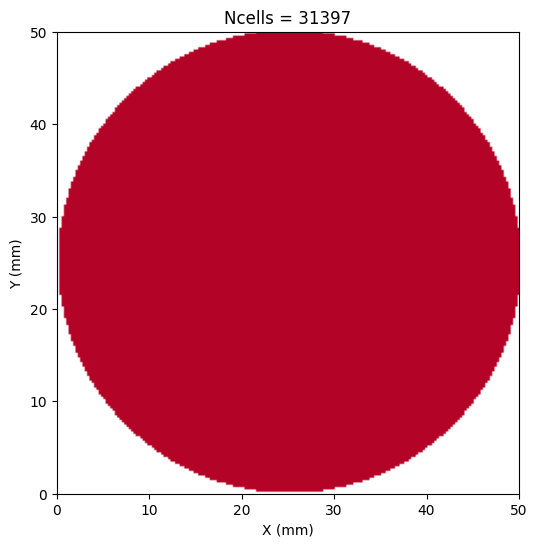

In [2]:
def create_mesh(n):
  # Keep grid locations inside the circle; leave the surrounding area inactive.
  x, y = np.meshgrid(np.arange(n), np.arange(n))
  X, Y = x.flatten(), y.flatten()
  R = np.sqrt((X - n / 2) ** 2 + (Y - n / 2) ** 2)
  R = R.reshape((n, n))
  mesh = np.zeros((n, n), dtype=np.uint8)
  mesh[np.abs(R) < n/2] = 1
  return mesh


GRID_SIZE = 200   # Number of grid nodes along each axis.
DR = 0.25         # Node spacing in mm: 200 * 0.25 = 50 mm across the domain.

mesh = create_mesh(GRID_SIZE)

tissue_cmap = plt.get_cmap("coolwarm_r")
tissue_cmap.set_under("white")
tissue_cmap.set_bad("black")

# Display the tissue mask; the counts below refer to computational tissue nodes.
plt.figure(figsize=(6, 6))
plt.title(f"Tissue Domain: {np.count_nonzero(mesh)} cells")
plt.imshow(mesh, cmap=tissue_cmap, extent=[0, 50, 0, 50], vmin=1, vmax=2, origin="lower")
plt.title(f"Ncells = {np.sum(mesh)}")
plt.xlabel("X (mm)")
plt.ylabel("Y (mm)")
plt.show()

### Visualization settings

Define the activation-time color scale and a reusable voltage-animation exporter. Voltage movies use a fixed −90 to +20 mV color range and mask the tissue exterior; playback speed is independent of simulated time.


In [ ]:
import numpy as np
from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvasAgg


def make_text_mask(shape, text, position=(10, 10), fontsize=24):
    """Position is (x, y) in pixels from the top-left corner."""
    height, width = shape[:2]
    fig = Figure(
        figsize=(width / 100, height / 100),
        dpi=100,
        facecolor="none",
    )
    canvas = FigureCanvasAgg(fig)

    x, y = position
    fig.text(
        x / width,
        1 - y / height,
        text,
        ha="left",
        va="top",
        fontsize=fontsize,
        color="white",
    )
    canvas.draw()

    return np.asarray(canvas.buffer_rgba())[..., 3].copy() > 0


def add_text(rgb_frame, frame_index, , color=(255, 255, 255)):
    mask = text_mask(frame_index) if callable(text_mask) else text_mask
    rgb_frame[mask] = color
    return rgb_frame


In [23]:
from pathlib import Path
import numpy as np
from finitewave_tools.animation import Frame2DRenderer, AnimationBuilder
from IPython.display import Video, display
from matplotlib.colors import ListedColormap


# Separate color scale for activation times (voltage movies use Spectral_r).
lat_cmap = ListedColormap(plt.get_cmap("hsv")(np.linspace(0, 0.9, 100)))
lat_cmap.set_over("black")
lat_cmap.set_under("white")
lat_cmap.set_bad("white")


def write_2d_animation(animation_name, frames, mask, dt=1, nan_mask=None, fps=24):
    """Export tracked voltage frames as an MP4, masking the exterior of the tissue."""
    output_dir = Path("./output")

    if not output_dir.exists():
        output_dir.mkdir(parents=True, exist_ok=True)

    frame_renderer = Frame2DRenderer()
    frame_renderer.set_frames(frames=frames)
    frame_renderer.configure_grid(np.ones((GRID_SIZE, GRID_SIZE)), upscale_factor=4)

    animation = AnimationBuilder()
    animation.frame_renderer = frame_renderer
    # Keep the same voltage scale across experiments; fps controls playback only.
    animation.write(
        path=output_dir,
        animation_name=animation_name,
        fps=fps,
        prog_bar=True,
        clim=(-90, 20),
        cmap="Spectral_r",
        output_mask=mask,
        nan_mask=nan_mask,
        callback=lambda rgb_frame, frame_index: add_text(
            rgb_frame,
            frame_index,
            text_mask=make_text_mask(
                shape=rgb_frame.shape,
                text=f"{frame_index * dt:.1f} ms",
                position=(10, 10),
                fontsize=24,
            )
        )
    )

    video_path = output_dir / f"{animation_name}.mp4"
    return video_path

### Paced propagation and activation mapping

Pace a narrow edge strip every 800 ms using the reference atrial model. Record the first sampled time each site exceeds −40 mV to build a local activation-time (LAT) map. Activation is sampled every 1 ms, and voltage maps are saved every 10 ms.


Running Courtemanche on (200, 200) Grid:   0%|          | 0/50000 [00:00<?, ?it/s]

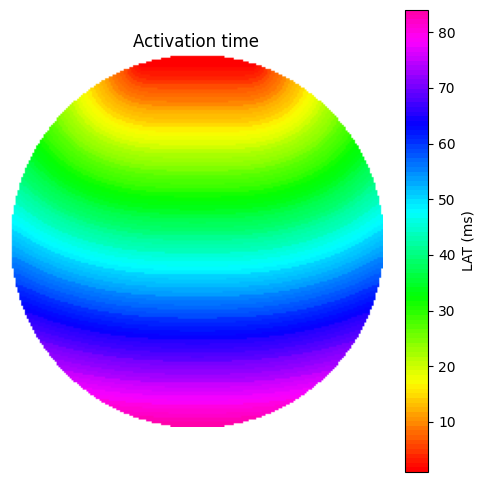

In [6]:
from IPython.display import Video, display
import finitewave as fw


T_MAX = 1000
SINUS_PERIOD = 800
EXP_NAME = "sinus_on_plate"

tissue = fw.CardiacTissue([GRID_SIZE, GRID_SIZE], dr=DR)
tissue.mesh = mesh.copy()

cardiac_model = fw.Courtemanche()
cardiac_model.prepacing(stim_prepacing)

# Pace a narrow edge strip at 0 and 800 ms during this 1000 ms simulation.
stim_sequence = fw.StimSequence()
for t_stim in np.arange(0, T_MAX, SINUS_PERIOD):
    stim_sequence.add_stim(fw.StimCurrentCoord(time=t_stim,
                                               curr_value=100,
                                               duration=1,
                                               x_min=0, x_max=5,
                                               y_min=0, y_max=GRID_SIZE))

# Record voltage maps and, where requested, a local action potential.
# At dt = 0.02 ms: frames every 10 ms; activation-time sampling every 1 ms.
frame_tracker = fw.FrameTracker(step=500, aggregate=True)
lat_tracker = fw.ActivationTimeTracker(step=50)

tracker_sequence = fw.TrackerSequence()
tracker_sequence.add_tracker(frame_tracker)
tracker_sequence.add_tracker(lat_tracker)

# Connect tissue, cell dynamics, pacing, and recordings to the simulation.
simulation = fw.CardiacSimulation(dt=0.02, t_max=T_MAX, backend="jax")
simulation.cardiac_tissue = tissue
simulation.cardiac_model = cardiac_model
simulation.stim_sequence = stim_sequence
simulation.tracker_sequence = tracker_sequence

# Advance the simulation and collect the requested recordings.
simulation.run()

# Map the first detected activation time at each tissue location.
plt.figure(figsize=(6, 6))
plt.imshow(lat_tracker.output, vmin=1, cmap=lat_cmap)
plt.colorbar(label="LAT (ms)")
plt.title("Activation time")
plt.axis("off")
plt.show()


### Paced propagation movie

Export and display the recorded voltage maps to show propagation and recovery across the circular sheet.


In [18]:
# Export only frames that were recorded, then display the voltage movie.
frames = frame_tracker.frames[:len(frame_tracker.tracking_times)]
dt_frames = simulation.dt * frame_tracker.step
video_path = write_2d_animation(EXP_NAME, frames, mask=(mesh==1), dt=dt_frames)
display(Video(str(video_path), embed=True, width=500))

Building animation:   0%|          | 0/101 [00:00<?, ?it/s]

### S1–S2 stimulation protocol

Define regular edge pacing (S1) and one premature stimulus (S2) covering a quarter of the grid. Regular pacing continues throughout the experiment; the premature stimulus can encounter partially recovered tissue and initiate reentry.


In [19]:
def build_s1s2_protocol(shape, t_max, basic_cycle_length, s2_time):
    """Combine repeated S1 edge pacing with one premature, spatially restricted S2."""
    stim_sequence = fw.StimSequence()
    # Keep the regular pacing train active for the full simulation.
    for t_stim in range(0, t_max, basic_cycle_length):
        stim_sequence.add_stim(fw.StimCurrentCoord(time=t_stim,
                                                   curr_value=30,
                                                   duration=2,
                                                   x_min=1, x_max=5,
                                                   y_min=1, y_max=shape[1]))

    # Stimulate a quarter of the grid early, while recovery may be spatially uneven.
    stim_sequence.add_stim(fw.StimCurrentCoord(time=s2_time,
                                               curr_value=30,
                                               duration=2,
                                               x_min=0, x_max=shape[0]//2,
                                               y_min=0 , y_max=shape[1]//2 ))
    return stim_sequence

### Reentry in remodeled tissue

Run the S1–S2 protocol with remodeled atrial tissue, an 800 ms pacing cycle length, and a premature stimulus at 150 ms. Display the voltage movie to show the resulting wave pattern.


In [21]:
T_MAX = 1000
BASIC_CYCLE_LENGTH = 800
S2_TIME = 150
EXP_NAME = "spiral_on_plate"

# Apply the remodeling parameters before adapting the cell to the pacing history.
cardiac_model = fw.Courtemanche()
cardiac_model.set_parameters(REMODELED_PARAMETERS)
cardiac_model.prepacing(stim_prepacing)

# Schedule regular S1 pacing and the premature S2 stimulus.
s1_s2_protocol = build_s1s2_protocol(mesh.shape, T_MAX, BASIC_CYCLE_LENGTH, S2_TIME)

# Create a fresh circular tissue sheet for this experiment.
tissue = fw.CardiacTissue([GRID_SIZE, GRID_SIZE], dr=DR)
tissue.mesh = mesh.copy()

# Record voltage maps and, where requested, a local action potential.
# A 300-step recording interval corresponds to 6 ms at dt = 0.02 ms.
frame_tracker = fw.FrameTracker(step=300, aggregate=True)
tracker_sequence = fw.TrackerSequence()
tracker_sequence.add_tracker(frame_tracker)

# Connect tissue, cell dynamics, pacing, and recordings to the simulation.
simulation = fw.CardiacSimulation(dt=0.02, t_max=T_MAX, backend="jax")
simulation.cardiac_tissue = tissue
simulation.cardiac_model = cardiac_model
simulation.stim_sequence = s1_s2_protocol
simulation.tracker_sequence = tracker_sequence

# Advance the simulation and collect the requested recordings.
simulation.run()

dt_frames = simulation.dt * frame_tracker.step
frames = frame_tracker.frames[:len(frame_tracker.tracking_times)]
video_path = write_2d_animation(EXP_NAME, frames, mask=(mesh==1), dt=dt_frames)
display(Video(str(video_path), embed=True, width=500))

Running Courtemanche on (200, 200) Grid:   0%|          | 0/50000 [00:00<?, ?it/s]

Building animation:   0%|          | 0/167 [00:00<?, ?it/s]

### Timed ionic and tissue-coupling changes

Repeat the remodeled-tissue experiment and apply an intervention at 500 ms: reduce `gkr` and `gkur` to the specified values and increase the diffusion coefficient fivefold. The resulting movie therefore reflects changes in both ionic currents and tissue coupling. A local action potential is also recorded.


In [27]:
class AddDrug(fw.Command):
    """Apply a timed Courtemanche conductance change and diffusion increase."""
    def __init__(self, time):
        super().__init__(time)

    def execute(self, simulation):
        # Change the ionic parameters and refresh values used by the numerical kernel.
        simulation.cardiac_model.set_parameters(DRUG_PARAMETERS)
        simulation.cardiac_model.collect_kernel_args()
        # Separately increase tissue coupling and rebuild the propagation operator.
        simulation.cardiac_model.D_model *= 5.
        simulation.spatial_discretization.update_weights()
        simulation.time_integration.assemble_system()


T_MAX = 1000
T_DRUG = 500
BASIC_CYCLE_LENGTH = 800
S2_TIME = 150
EXP_NAME = "drug_on_plate"

# Schedule the combined ionic and diffusion change at 500 ms.
command_sequence = fw.CommandSequence()
command_sequence.add_command(AddDrug(T_DRUG))

cardiac_model = fw.Courtemanche()
cardiac_model.set_parameters(REMODELED_PARAMETERS)
cardiac_model.prepacing(stim_prepacing)

# Schedule regular S1 pacing and the premature S2 stimulus.
stim_sequence = build_s1s2_protocol(mesh.shape, T_MAX, BASIC_CYCLE_LENGTH, S2_TIME)

# Create a fresh circular tissue sheet for this experiment.
tissue = fw.CardiacTissue([GRID_SIZE, GRID_SIZE], dr=DR)
tissue.mesh = mesh.copy()

# Record voltage maps.
frame_tracker = fw.FrameTracker(step=300, aggregate=True)
tracker_sequence = fw.TrackerSequence()
tracker_sequence.add_tracker(frame_tracker)

# Connect tissue, cell dynamics, pacing, and recordings to the simulation.
simulation = fw.CardiacSimulation(dt=0.02, t_max=T_MAX, backend="jax")
simulation.cardiac_tissue = tissue
simulation.cardiac_model = cardiac_model
simulation.stim_sequence = stim_sequence
simulation.tracker_sequence = tracker_sequence
simulation.command_sequence = command_sequence

# Advance the simulation and collect the requested recordings.
simulation.run()

dt_frames = simulation.dt * frame_tracker.step
frames = frame_tracker.frames[:len(frame_tracker.tracking_times)]
video_path = write_2d_animation(EXP_NAME, frames, mask=(mesh==1), dt=dt_frames, fps=15)
display(Video(str(video_path), embed=True, width=500))

Running Courtemanche on (200, 200) Grid:   0%|          | 0/50000 [00:00<?, ?it/s]

Building animation:   0%|          | 0/167 [00:00<?, ?it/s]

### Whole-tissue stimulation (Optical Defibrilation)

Apply a 1 ms current pulse across the tissue at 800 ms and display the subsequent activity. This is an idealized simultaneous stimulus, rather than a clinical shock-field simulation. The regular pacing protocol remains active, including an S1 stimulus at 800 ms.


In [28]:
EXP_NAME = "defib_on_plate"
T_MAX = 1000
T_DEFIB = 800
BASIC_CYCLE_LENGTH = 800
S2_TIME = 150

cardiac_model = fw.Courtemanche()
cardiac_model.set_parameters(REMODELED_PARAMETERS)
cardiac_model.prepacing(stim_prepacing)

# Schedule regular S1 pacing and the premature S2 stimulus.
stim_sequence = build_s1s2_protocol(mesh.shape, T_MAX, BASIC_CYCLE_LENGTH, S2_TIME)
# Add the whole-domain pulse; the scheduled S1 stimuli are retained.
stim_sequence.add_stim(fw.StimCurrentCoord(time=T_DEFIB, curr_value=30, duration=1,
                                           x_min=0, x_max=GRID_SIZE,
                                           y_min=0, y_max=GRID_SIZE ))
# Create a fresh circular tissue sheet for this experiment.
tissue = fw.CardiacTissue([GRID_SIZE, GRID_SIZE], dr=DR)
tissue.mesh = mesh.copy()

# Record voltage maps.
frame_tracker = fw.FrameTracker(step=300, aggregate=True)
tracker_sequence = fw.TrackerSequence()
tracker_sequence.add_tracker(frame_tracker)

# Connect tissue, cell dynamics, pacing, and recordings to the simulation.
simulation = fw.CardiacSimulation(dt=0.02, t_max=T_MAX, backend="jax")
simulation.cardiac_tissue = tissue
simulation.cardiac_model = cardiac_model
simulation.stim_sequence = stim_sequence
simulation.tracker_sequence = tracker_sequence

# Advance the simulation and collect the requested recordings.
simulation.run()

dt_frames = simulation.dt * frame_tracker.step
frames = frame_tracker.frames[:len(frame_tracker.tracking_times)]
video_path = write_2d_animation(EXP_NAME, frames, mask=(mesh==1), dt=dt_frames, fps=15)
display(Video(str(video_path), embed=True, width=500))

Running Courtemanche on (200, 200) Grid:   0%|          | 0/50000 [00:00<?, ?it/s]

Building animation:   0%|          | 0/167 [00:00<?, ?it/s]

## 3. Real patient geometry simulation

Simulate atrial activity and prescribed ablation lines on the supplied patient atrial surface. The electrical parameters and initial activation pattern are model inputs, rather than patient-specific electrical measurements.

### Download the geometry dataset

Download the example repository containing the atrial surface, anatomical labels, ablation lines, and initial phase map. Skip the download if the repository already exists in the working directory.


In [93]:
import numpy as np

# Download the example data; skip this command if the checkout already exists.
!git clone --depth 1 https://github.com/finitewave/Finitewave-Tools.git

Cloning into 'Finitewave-Tools'...
remote: Enumerating objects: 112, done.
remote: Counting objects: 100% (112/112), done.
remote: Compressing objects: 100% (102/102), done.
remote: Total 112 (delta 2), reused 88 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (112/112), 29.09 MiB | 20.53 MiB/s, done.
Resolving deltas: 100% (2/2), done.


### Load anatomy and ablation locations

Load the surface coordinates, triangle connectivity, anatomical node sets, lesion lines, and initial phase map. MV denotes the mitral valve; LPV and RPV denote the left and right pulmonary veins. The path assumes Google Colab; adjust it to the local dataset directory when running elsewhere.


In [ ]:
from pathlib import Path

# Colab data location: adjust this path when running locally.
path = Path("/content/Finitewave-Tools/Tutorials/data/atrial")
# path = Path("../../Finitewave-Tools/Tutorials/data/atrial")

# Surface coordinates and triangular connectivity define the atrial geometry.
points = np.load(path / "points.npy")
elems = np.load(path / "elems.npy")
# Anatomical node sets and prescribed lesion lines refer to this mesh numbering.
mv_ids = np.load(path / "mv_ids.npy")
lpv_ids = np.load(path / "lpv_ids.npy")
rpv_ids = np.load(path / "rpv_ids.npy")
pv_ids = np.load(path / "pv_ids.npy")
roof_line_ids = np.load(path / "roof_line_ids.npy")
mv_lpv_line_ids = np.load(path / "mv_lpv_line_ids.npy")
# The phase template sets the initial position within the electrical cycle at each node.
init_phase = np.load(path / "init_phase.npy")


### Initialize atrial electrical activity

Record an action potential and its associated gating variables and ion concentrations in a short tissue strip. Use the supplied phase map to assign a recorded electrical state to each atrial location. Plot the initial phase and membrane voltage on the atrial surface.


Running Courtemanche on (50, 1) Grid:   0%|          | 0/25000 [00:00<?, ?it/s]

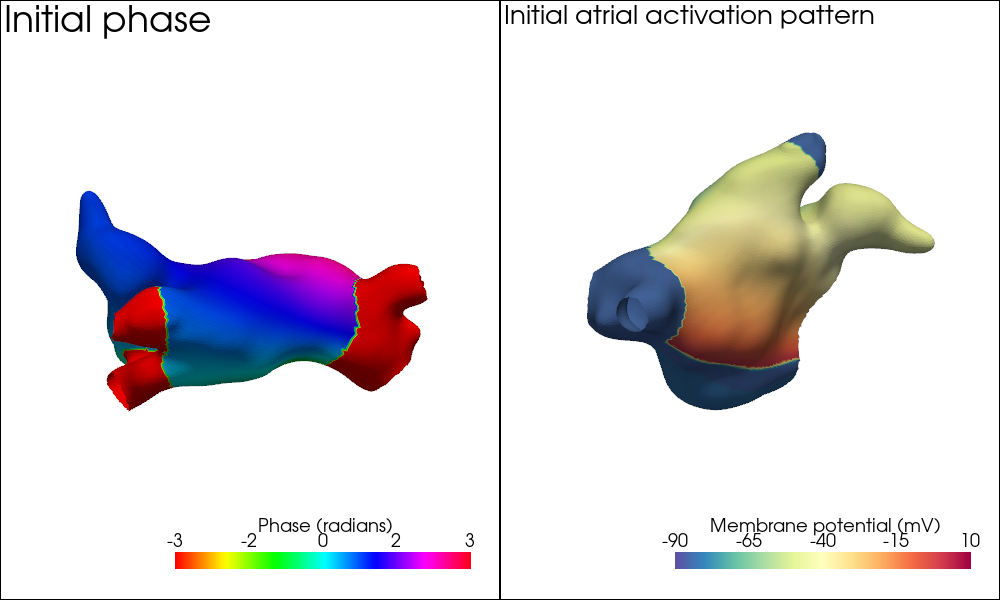

In [76]:

import numpy as np
import pyvista as pv

import finitewave as fw
import numpy as np


# Atrial-surface remodeling parameters; this set also increases gKr.
remodeled_params =dict(
    gk1 = 2 * 0.09,
    gks = 2 * 0.129,
    gkr = 1.6 * 0.0294,
    gkur = 0.5 * 1.0,
    gcal = 0.45 * 0.1238,
    gto = 0.35 * 0.1652,
    ipcamax = 1.5 * 0.6,
    inacamax = 1.6 * 1600.0
)

# Adapt the model with 100 beats at 1000 ms, then 100 beats at 500 ms.
stim_prepacing = fw.StimSingleCell(dt=0.01)
stim_prepacing.add_stim(n_beats=100, cycle_length=1000, duration=1, curr_value=0.5)
stim_prepacing.add_stim(n_beats=100, cycle_length=500, duration=1, curr_value=0.5)

cardiac_model = fw.Courtemanche()
cardiac_model.set_parameters(remodeled_params)
cardiac_model.prepacing(stim_prepacing)

# Use a 50 x 1 strip to record a library of local action-potential states.
n, m = 50, 1
tissue = fw.CardiacTissue([n, m], dr=0.25)

# Stimulate one end of the strip to generate a propagating action potential.
stim_sequence = fw.StimSequence()
stim_sequence.add_stim(fw.StimCurrentCoord(time=0, curr_value=100, duration=2,
                                           x_min=0, x_max=1, y_min=0, y_max=m))

# Record all state variables at the midpoint every 10 steps (0.1 ms).
state_tracker = fw.MultiVariableTracker(node_inds=[(n//2, m//2)], step=10, start_time=0)
tracker_sequence = fw.TrackerSequence()
tracker_sequence.add_tracker(state_tracker)

# Connect tissue, cell dynamics, pacing, and recordings to the simulation.
simulation = fw.CardiacSimulation(dt=0.01, t_max=250, backend="numba")
simulation.cardiac_model = cardiac_model
simulation.cardiac_tissue = tissue
simulation.stim_sequence = stim_sequence
simulation.tracker_sequence = tracker_sequence

# Advance the simulation and collect the requested recordings.
simulation.run()

# Map each atrial phase value to a recorded time sample, including gates and ions.
state_vars = {}
n_levels = len(state_tracker.tracking_times)
state_map = n_levels - np.digitize(init_phase, bins=np.linspace(-np.pi, np.pi, n_levels))
state_map[pv_ids] = 0
for var_name in cardiac_model.state_vars:
    tracked_values = state_tracker.output[var_name]
    var_array = tracked_values[state_map]
    state_vars[var_name] = var_array


# Show the prescribed phase template beside the resulting initial membrane voltage.
pv.set_jupyter_backend("static")

poly = pv.PolyData(points, np.pad(elems, ((0, 0), (1, 0)), constant_values=3))

pl = pv.Plotter(shape=(1, 2), window_size=(1000, 600))
pl.subplot(0, 0)
pl.add_text("Initial phase", position="upper_left", font_size=16, color="black")
pl.add_mesh(poly, scalars=init_phase, show_edges=False, cmap="hsv", clim=(-np.pi, np.pi),
            nan_color="lightgray", copy_mesh=True, show_scalar_bar=True,
            scalar_bar_args={"title": "Phase (radians)",
                             "color": "black", "n_labels": 5, "fmt": "%.0f"})
pl.camera_position = "xy"
pl.subplot(0, 1)
pl.add_text("Initial atrial activation pattern", position="upper_left", font_size=16, color="black")
pl.add_mesh(poly, scalars=state_vars["u"], show_edges=False, cmap="Spectral_r", clim=(-90.0, 10.0),
            nan_color="lightgray", copy_mesh=True, show_scalar_bar=True,
            scalar_bar_args={"title": "Membrane potential (mV)",
                             "color": "black", "n_labels": 5, "fmt": "%.0f"})
pl.camera_position = "iso"

pl.show()


### Simulate ablation and record the ECG

Start with nonconducting left and right pulmonary-vein regions, then introduce a roof line at 750 ms and a mitral-to-left-pulmonary-vein line at 1900 ms. Lesions act as immediate conduction barriers. Apply focal pacing every 800 ms and record voltage maps and a single virtual-lead ECG signal. Red markers indicate ablation times; green markers indicate pacing times.


/Users/arstanbekokenov/Projects/Finitewave/finitewave/numerics/time_integration/forward_euler_time_integration.py:135: RuntimeWarning: divide by zero encountered in divide
  mass_lumped_inv = sparse.diags(1 / mass.sum(axis=1).A1)
/Users/arstanbekokenov/Projects/Finitewave/finitewave/numerics/time_integration/forward_euler_time_integration.py:159: RuntimeWarning: divide by zero encountered in divide
  mass_lumped_inv = sparse.diags(1 / mass.sum(axis=1).A1)


Running Courtemanche on Triangle Elements:   0%|          | 0/140000 [00:00<?, ?it/s]

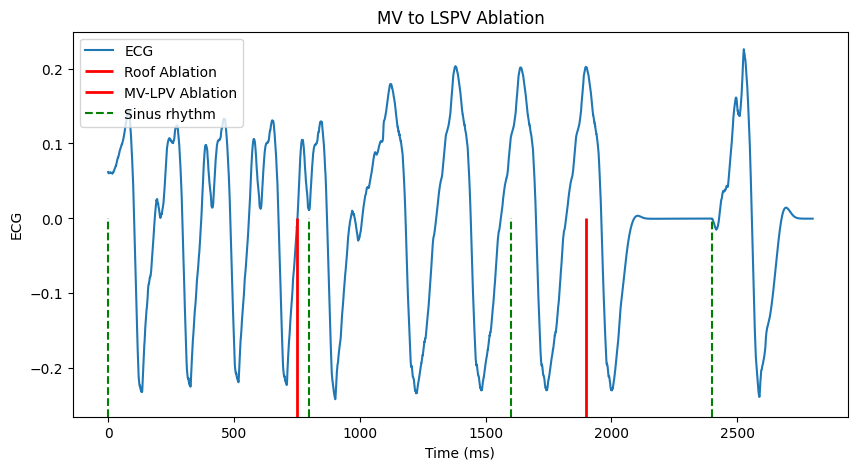

In [ ]:
import matplotlib.pyplot as plt


U_REST = state_vars["u"].min()


class Ablate(fw.Command):
    """Turn selected mesh nodes into a conduction barrier at a scheduled time."""
    def __init__(self, time, ablation_ids):
        super().__init__(time=time)
        self.ablation_ids = ablation_ids

    def execute(self, simulation):
        ablation_ids = simulation.backend.wrap_indexes(self.ablation_ids)
        # Mark the lesion nodes as nonconducting and update tissue connectivity.
        simulation.cardiac_tissue.mesh[ablation_ids] = 2
        simulation.spatial_discretization.update_weights()
        simulation.time_integration.assemble_system()
        # Reset lesion voltage in both the cell model and the time integrator.
        simulation.cardiac_model._u = simulation.backend.set_flat_values(
            simulation.cardiac_model._u, ablation_ids, U_REST
        )
        simulation.time_integration.u = simulation.backend.set_flat_values(
            simulation.time_integration.u, ablation_ids, U_REST
        )
        simulation.time_integration.u_old = simulation.backend.set_flat_values(
            simulation.time_integration.u_old, ablation_ids, U_REST
        )

# Experiment controls: intervention and pacing times in ms.
ROOF_ABL_TIME = 750
MV_LPV_ABL_TIME = 1900
SINUS_PERIOD = 800
T_MAX = 2800
LEAD_COORDS = np.mean(points, axis=0) + np.array([0, +50, 0])
SINUS_NODE_ID = 9846

cardiac_tissue = fw.CardiacTissue(coords=points, elems=elems,
                                  elem_type=fw.ElementType.TRIANGLE)
# These pulmonary-vein barriers are present before the first simulation step.
cardiac_tissue.mesh[lpv_ids] = 2
cardiac_tissue.mesh[rpv_ids] = 2

# Add the roof line first and the mitral-to-left-PV line later.
command_sequence = fw.CommandSequence()
command_sequence.add_command(Ablate(time=ROOF_ABL_TIME, ablation_ids=roof_line_ids))
command_sequence.add_command(Ablate(time=MV_LPV_ABL_TIME, ablation_ids=mv_lpv_line_ids))

# Initialize the atrium from the full phase-mapped state prepared above.
cardiac_model = fw.Courtemanche()
cardiac_model.set_parameters(remodeled_params)
cardiac_model.set_variables(state_vars)

# Drive periodic focal pacing from a selected node on this particular mesh.
stim_sequence = fw.StimSequence()
for sinus_time in np.arange(0, T_MAX, SINUS_PERIOD):
    stim_sequence.add_stim(
        fw.StimCurrentElectrodes(time=sinus_time, curr_value=30, duration=1,
                                 coords=points[SINUS_NODE_ID], size=3.0)
        )

# Save voltage maps every 10 ms and the virtual-lead signal every 0.4 ms.
anim_tracker = fw.AnimationTracker(step=500, start_time=0, animation_name="lspv_to_ripv_ablation")
ecg_tracker = fw.LeadFieldECGTracker(lead_coords=LEAD_COORDS, volume_conductivity=0.3,
                                     step=20, start_time=0)
tracker_sequence = fw.TrackerSequence()
tracker_sequence.add_tracker(anim_tracker)
tracker_sequence.add_tracker(ecg_tracker)

# Run the atrial-surface simulation with the JAX backend and explicit time stepping.
simulation = fw.CardiacSimulation(dt=0.02, t_max=T_MAX, backend="jax")
simulation.cardiac_tissue = cardiac_tissue
simulation.cardiac_model = cardiac_model
simulation.stim_sequence = stim_sequence
simulation.time_integration = fw.ForwardEulerTimeIntegration()
simulation.tracker_sequence = tracker_sequence
simulation.command_sequence = command_sequence

simulation.run()

# Align the simulated ECG with lesion times (red) and pacing times (green).
plt.figure(figsize=(10, 5))
plt.plot(ecg_tracker.tracking_times, ecg_tracker.output, label="ECG")
ymin = plt.ylim()[0]
ymax = plt.ylim()[1]
plt.vlines(x=ROOF_ABL_TIME, ymin=ymin, ymax=0, color="red", linestyle="-",
           label="Roof Ablation", lw=2)
plt.vlines(x=MV_LPV_ABL_TIME, ymin=ymin, ymax=0, color="red", linestyle="-",
           label="MV-LPV Ablation", lw=2)
for stim_time in np.arange(0, T_MAX, SINUS_PERIOD):
    plt.vlines(x=stim_time, ymin=ymin, ymax=0, color="green", linestyle="--",
               label="Sinus rhythm" if stim_time == 0 else None)
plt.ylim(ymin, ymax)
plt.xlabel("Time (ms)")
plt.ylabel("ECG")
plt.title("MV to LSPV Ablation")
plt.legend()
plt.show()

### Render atrial propagation

Export the saved voltage maps as a surface animation with simulated time and red markers for the initial pulmonary-vein barriers and subsequent roof line. The second ablation line is included in the simulation and ECG timing markers, but is not drawn by this rendering routine. Videos are saved in `./output`.


In [ ]:
from pathlib import Path
import numpy as np
import finitewave_tools.visualization as vis
import finitewave_tools.animation as anim


def change_camera_and_ablation(renderer, frame_index, ablation_frames, 
                               ablation_lines, pv_ablation_lines):
    # Convert frame number to simulated time, independently of movie playback speed.
    dt = simulation.dt * anim_tracker.step
    renderer.plotter.add_text(
        f"Time: {frame_index * dt:.2f} ms",
        position="upper_right",
        font_size=16,
        color="black",
        name="frame_label",
    )

    # Show the pre-existing PV barriers from the first frame.
    if frame_index == 0:
        renderer.plotter.camera_position = "iso"
        renderer.plotter.add_points(
            points[pv_ablation_lines],
            color="red",
            point_size=30,
            render_points_as_spheres=True,
        )

    # Add the ablation-line when that intervention takes effect.
    if frame_index in ablation_frames:
        for i, _ in enumerate(ablation_frames):
            if frame_index == ablation_frames[i]:
                abl_line = ablation_lines[i]
                break

        renderer.plotter.add_points(
            points[abl_line],
            color="red",
            point_size=30,
            render_points_as_spheres=True,
        )

    if frame_index == int(0.5 * (ablation_frames[0] + ablation_frames[1])):
        renderer.plotter.camera_position = "zy"

    if frame_index == (ablation_frames[1] + 40):
        renderer.plotter.camera_position = "iso"


# Translate the roof intervention time into its corresponding saved frame.
ablation_frames = [int(ROOF_ABL_TIME / (simulation.dt * anim_tracker.step)),
                   int(MV_LPV_ABL_TIME / (simulation.dt * anim_tracker.step))]

ablation_lines = [roof_line_ids, mv_lpv_line_ids]
pv_ablation_lines = np.concatenate([lpv_ids, rpv_ids])

def render_callback(renderer, frame_index):
    change_camera_and_ablation(renderer, frame_index, ablation_frames,
                               ablation_lines, pv_ablation_lines)

animation_name = "lspv_to_ripv_ablation"

path = Path("./data")
scalar_name = "Membrane potential (mV)"
animation_grid = vis.PyVistaSurfaceGrid(points, elems)

# Read the saved simulation frames and render them on the original atrial surface.
renderer = anim.Frame3DRenderer()
renderer.set_frames(f"./{animation_name}",)
renderer.configure_grid(animation_grid, window_size=(1920, 1080))

output_dir = Path("./output")
output_dir.mkdir(parents=True, exist_ok=True)

animation = anim.AnimationBuilder()
animation.frame_renderer = renderer
# Export with a consistent voltage scale; fps sets viewing speed, not simulation dt.
animation.write(
    path=output_dir,
    animation_name=animation_name,
    fps=10,
    prog_bar=True,
    scalar_name=scalar_name,
    cmap="Spectral_r",
    nan_color="white",
    clim=(-90.0, 20.0),
    callback=render_callback
)

video_path = output_dir / f"{animation_name}.mp4"


[75, 190]


Building animation:   0%|          | 0/281 [00:00<?, ?it/s]

### Display the atrial animation

Play the exported movie to follow atrial activation before and after the prescribed interventions.


In [73]:
from IPython.display import Video, display

# Play the exported atrial animation within the notebook.
display(Video(str(video_path), embed=True, width=800))